1. Import libraries and load the dataset

The dataset is distributed by scikit-learn and originates from the Wisconsin Diagnostic Breast Cancer dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

RANDOM_STATE = 42
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
df.drop(columns=["target"], inplace=True)

print("Dataset shape:", df.shape)
print("Predictor feature count:", len(data.feature_names))
display(df.head())


Dataset shape: (569, 31)
Predictor feature count: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


2. Dataset understanding and data-quality checks

Check data types, missing cells, duplicate rows, class balance and descriptive statistics before modeling.

In [2]:
print("Data types:")
display(df.dtypes.value_counts().rename("column_count").to_frame())
print("Missing values per column (non-zero only):")
display(df.isna().sum()[df.isna().sum() > 0])
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Diagnosis counts:")
display(df["diagnosis"].value_counts().to_frame("count"))
print("Descriptive statistics:")
display(df.describe().T)


Data types:


,column_count
float64,30
object,1


Missing values per column (non-zero only):


,0


Total missing cells: 0
Duplicate rows: 0
Diagnosis counts:


,count
diagnosis,
benign,357
malignant,212


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


3. Exploratory data analysis and visualizations

Each chart includes a purpose and a short interpretation.

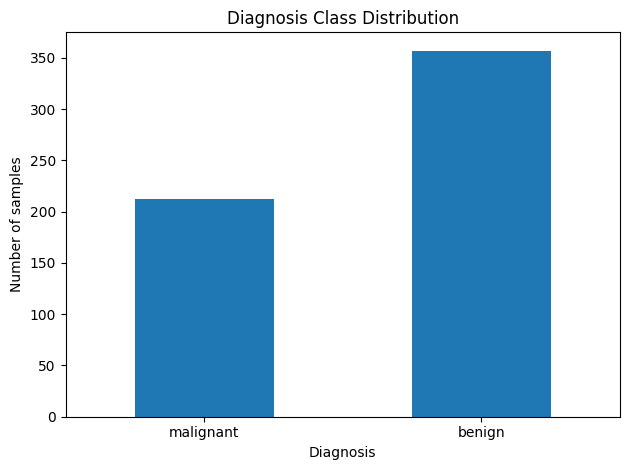

In [3]:
# Visualization 1: diagnosis class distribution
df["diagnosis"].value_counts().reindex(["malignant", "benign"]).plot(kind="bar")
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis"); plt.ylabel("Number of samples"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

Interpretation: The class-count plot shows the relative frequency of malignant and benign records. It helps identify class imbalance and supports the use of stratified splitting.

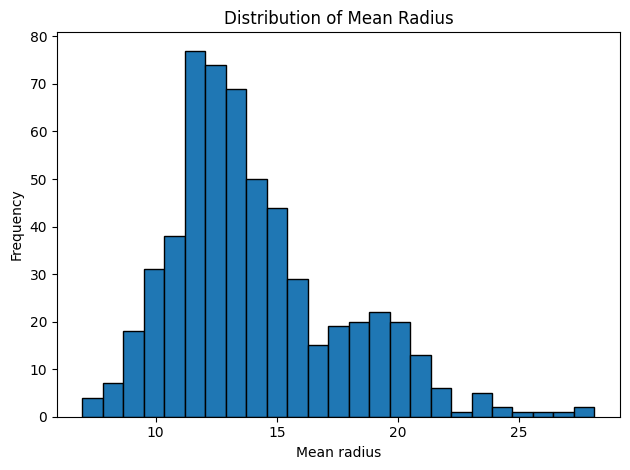

In [4]:
# Visualization 2: distribution of mean radius
plt.hist(df["mean radius"], bins=25, edgecolor="black")
plt.title("Distribution of Mean Radius")
plt.xlabel("Mean radius"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()

Interpretation: The histogram shows the shape and spread of mean-radius measurements and whether the distribution is symmetric or skewed.

/tmp/ipykernel_1768/2313449187.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["Malignant", "Benign"], showfliers=True)


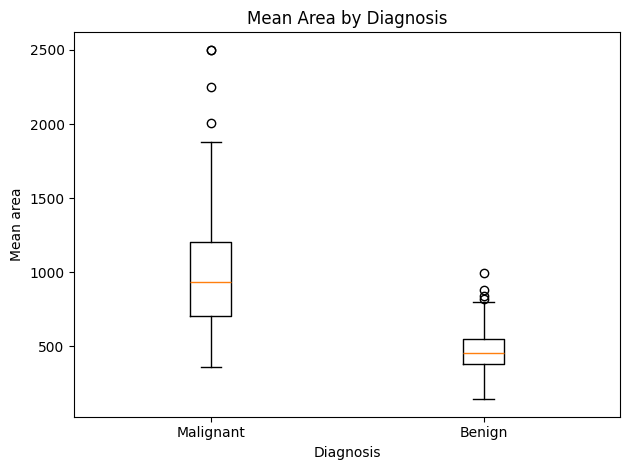

In [5]:
# Visualization 3: outlier/spread review by diagnosis
groups = [df.loc[df["diagnosis"] == label, "mean area"] for label in ["malignant", "benign"]]
plt.boxplot(groups, labels=["Malignant", "Benign"], showfliers=True)
plt.title("Mean Area by Diagnosis")
plt.xlabel("Diagnosis"); plt.ylabel("Mean area")
plt.tight_layout(); plt.show()

Interpretation: The boxplot compares median, interquartile range and potential extreme observations. The groups differ in their spread and central tendency, indicating that mean area may be informative. Outliers are inspected rather than automatically removed.

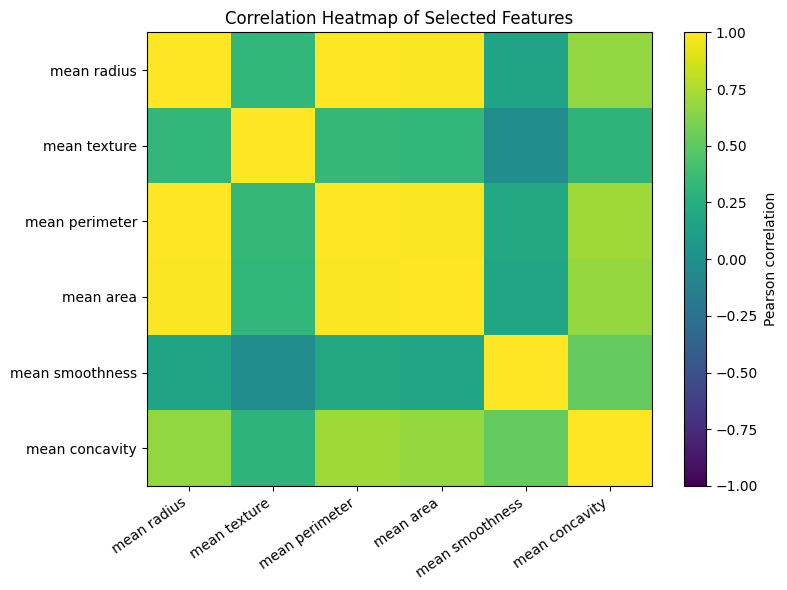

In [6]:
# Visualization 4: correlation heatmap for selected numeric features
selected = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "mean concavity"]
corr = df[selected].corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(selected)), selected, rotation=35, ha="right")
plt.yticks(range(len(selected)), selected)
plt.title("Correlation Heatmap of Selected Features")
plt.tight_layout(); plt.show()

Interpretation: The heatmap highlights linear associations among selected measurements. Strongly correlated size features may contain overlapping information; correlation alone does not establish causation.

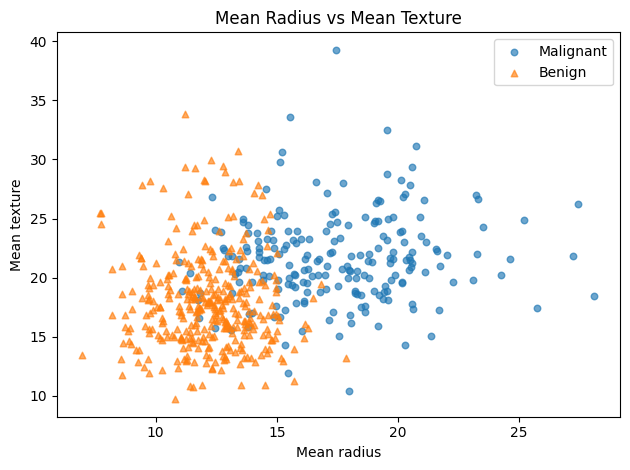

In [7]:
# Visualization 5: relationship between mean radius and mean texture
for label, marker in [("malignant", "o"), ("benign", "^")]:
    subset = df[df["diagnosis"] == label]
    plt.scatter(subset["mean radius"], subset["mean texture"], label=label.title(),
                marker=marker, alpha=0.65, s=22)
plt.title("Mean Radius vs Mean Texture")
plt.xlabel("Mean radius"); plt.ylabel("Mean texture"); plt.legend()
plt.tight_layout(); plt.show()

Interpretation: The scatterplot reveals relationships and overlap between the two features across diagnosis groups. Overlap means a single pair of features is unlikely to perfectly separate the classes on its own.

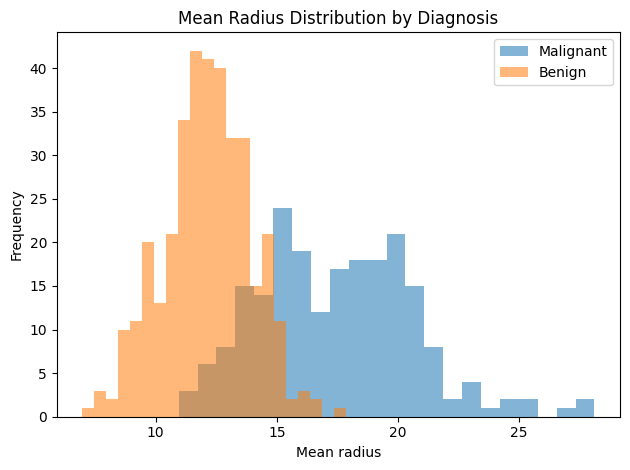

In [8]:
# Visualization 6: compare mean-radius distributions by diagnosis
for label in ["malignant", "benign"]:
    plt.hist(df.loc[df["diagnosis"] == label, "mean radius"], bins=22, alpha=0.55, label=label.title())
plt.title("Mean Radius Distribution by Diagnosis")
plt.xlabel("Mean radius"); plt.ylabel("Frequency"); plt.legend()
plt.tight_layout(); plt.show()

Interpretation: This overlay compares the feature distributions by class and shows whether the classes have different typical values and how much their ranges overlap.

4. Train / validation / test split and preprocessing

Use a stratified 70/15/15 split. Fit imputation and standardization on training data only.

In [9]:
feature_cols = list(data.feature_names)
X = df[feature_cols].copy()
y = data.target.copy()  # 0 = malignant, 1 = benign

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
X_val_scaled = scaler.transform(imputer.transform(X_val))
X_test_scaled = scaler.transform(imputer.transform(X_test))

print(f"Train: {len(X_train)} ({len(X_train)/len(X):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(X):.1%})")
print(f"Test: {len(X_test)} ({len(X_test)/len(X):.1%})")


Train: 398 (69.9%)
Validation: 85 (14.9%)
Test: 86 (15.1%)


5. Deep Learning model and basic hyperparameter tuning

A Multilayer Perceptron (MLP) is used for binary classification. Compare hidden-layer layouts and regularization strengths using validation accuracy. The test set remains held out until final evaluation.

In [10]:
configs = [
    {"hidden_layer_sizes": (32,), "alpha": 0.0001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.0001},
    {"hidden_layer_sizes": (32,), "alpha": 0.01},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.01},
]
tuning_rows = []
for cfg in configs:
    candidate = MLPClassifier(
        hidden_layer_sizes=cfg["hidden_layer_sizes"], activation="relu",
        solver="adam", alpha=cfg["alpha"], learning_rate_init=0.001,
        max_iter=350, random_state=RANDOM_STATE, early_stopping=True,
        validation_fraction=0.15, n_iter_no_change=25
    )
    candidate.fit(X_train_scaled, y_train)
    val_pred = candidate.predict(X_val_scaled)
    tuning_rows.append({
        "hidden_layer_sizes": str(cfg["hidden_layer_sizes"]),
        "alpha": cfg["alpha"],
        "validation_accuracy": accuracy_score(y_val, val_pred)
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values("validation_accuracy", ascending=False)
display(tuning_df)
best = tuning_df.iloc[0]
best_layers = eval(best["hidden_layer_sizes"])
best_alpha = float(best["alpha"])
print("Selected configuration:", best_layers, "| alpha =", best_alpha)

,hidden_layer_sizes,alpha,validation_accuracy
1,"(64, 32)",0.0001,0.988235
3,"(64, 32)",0.0100,0.988235
0,"(32,)",0.0001,0.976471
2,"(32,)",0.0100,0.976471


Selected configuration: (64, 32) | alpha = 0.0001


6. Train the selected MLP and track learning curves

The selected architecture is trained for 100 epochs while recording training loss and validation accuracy. This curve is useful for reviewing learning progress; epoch-by-epoch warm-start training is used for visualization.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691

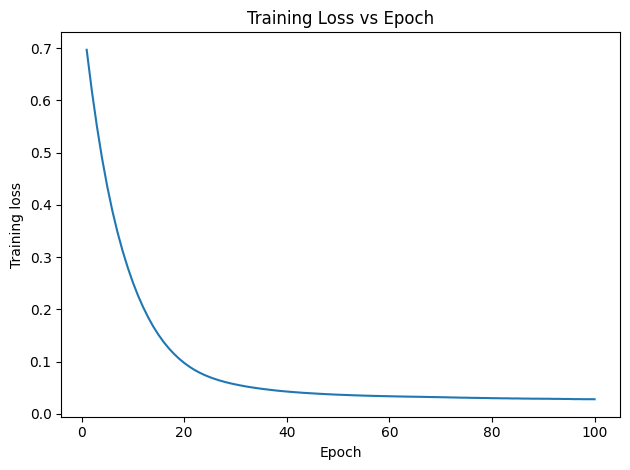

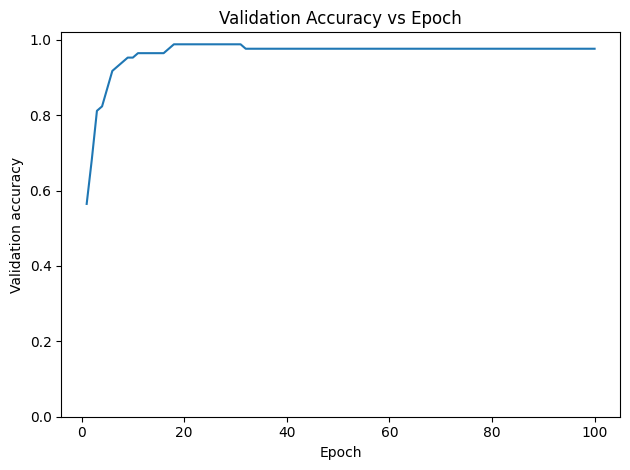

In [11]:
model = MLPClassifier(
    hidden_layer_sizes=best_layers, activation="relu", solver="adam",
    alpha=best_alpha, learning_rate_init=0.001, max_iter=1,
    warm_start=True, random_state=RANDOM_STATE, early_stopping=False, shuffle=True
)
train_losses, val_accuracies = [], []
for epoch in range(1, 101):
    model.fit(X_train_scaled, y_train)
    train_losses.append(float(model.loss_))
    val_accuracies.append(float(accuracy_score(y_val, model.predict(X_val_scaled))))

fig, ax = plt.subplots()
ax.plot(range(1, 101), train_losses)
ax.set(title="Training Loss vs Epoch", xlabel="Epoch", ylabel="Training loss")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
ax.plot(range(1, 101), val_accuracies)
ax.set(title="Validation Accuracy vs Epoch", xlabel="Epoch", ylabel="Validation accuracy")
ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

7. Final test-set evaluation

Accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC are calculated on the held-out test set. Class 1 is benign; the ROC curve uses the predicted probability of benign.

Accuracy: 0.9535
Precision (benign): 0.9464
Recall (benign): 0.9815
F1-score (benign): 0.9636
ROC-AUC (benign score): 0.9936
              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        32
      benign       0.95      0.98      0.96        54

    accuracy                           0.95        86
   macro avg       0.96      0.94      0.95        86
weighted avg       0.95      0.95      0.95        86



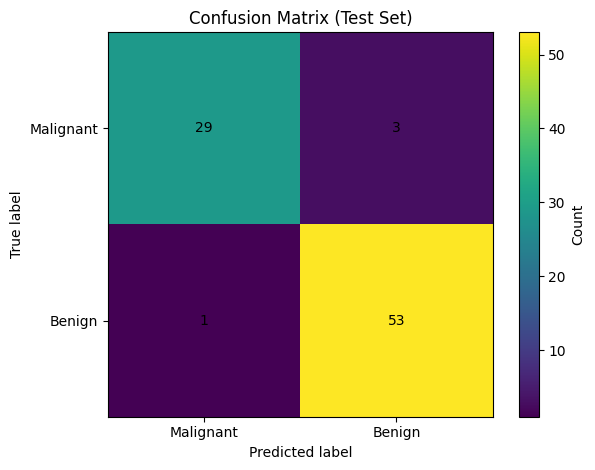

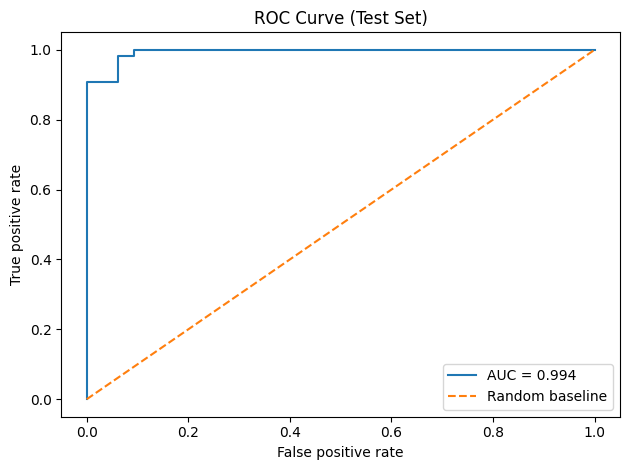

In [12]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision (benign):", round(precision_score(y_test, y_pred, pos_label=1, zero_division=0), 4))
print("Recall (benign):", round(recall_score(y_test, y_pred, pos_label=1, zero_division=0), 4))
print("F1-score (benign):", round(f1_score(y_test, y_pred, pos_label=1, zero_division=0), 4))
print("ROC-AUC (benign score):", round(roc_auc_score(y_test, y_prob), 4))
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"], zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.imshow(cm)
plt.title("Confusion Matrix (Test Set)")
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.xticks([0, 1], ["Malignant", "Benign"]); plt.yticks([0, 1], ["Malignant", "Benign"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.colorbar(label="Count")
plt.tight_layout(); plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=1)
auc = roc_auc_score(y_test, y_prob)
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("ROC Curve (Test Set)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.legend()
plt.tight_layout(); plt.show()